# Graphs and temporal models from scratch

Build node/edge tensors, message passing, a trainable NumPy graph classifier and causal history representations.

Download the bounded real sample first with `python scripts/download_data.py` from the repository root. Run cells in order. Each notebook can start a fresh kernel. Only data ingestion and pitch drawing use shared helpers; calculations below use NumPy/pandas/SciPy directly. Raw files remain excluded from Git. The sample contains one partial first half, so supervised-model training requires additional labeled matches for meaningful evaluation.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'workshop.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from workshop import load_data, pitch  # ingestion and drawing only; methods below are explicit
dataset, wide, tracking, metadata, events, phases, raw = load_data()
tracking = tracking.sort_values(['player_id','period_id','frame_id']).copy()
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
observed = tracking.dropna(subset=['x','y'])
frame_id = int(observed.groupby(['period_id','frame_id']).size().loc[lambda s:s.eq(22)].index[20][1])
snapshot = observed[observed.frame_id.eq(frame_id)].copy()
keepers = {str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels = {str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
print('Real match 1925299; loaded frames:', wide.shape[0], '| illustrative frame:', frame_id)

Real match 1925299; loaded frames: 6153 | illustrative frame: 61


## Construct graph tensors
Use a radius graph for this transparent baseline. Nodes are players, edge weights indicate spatial neighbors, and features contain normalized position and a home-team indicator. For actual GraphEPV training, orient coordinates to the possession team and encode attacking/defending identity consistently; the home-team indicator here only illustrates tensor construction. Compare this to UnravelSports' split-team/ball topology in the main walkthrough. Graph construction is a modeling decision, not a neutral preprocessing step. [UnravelSports](https://unravelsports.readthedocs.io/en/latest/tutorials/soccer_gnn.html).

,x_scaled,y_scaled,team
11897,-0.452571,-0.264118,0.0
287934,0.102667,0.147941,1.0
50982,-0.489714,0.685882,0.0
50999,0.694286,0.025294,1.0
51002,-0.084000,0.048529,1.0
51043,-0.139429,0.952647,1.0
51050,0.164762,0.020294,1.0
51694,-0.322857,0.350882,0.0
560882,-0.141524,0.285882,1.0
560983,0.141714,-0.196176,1.0


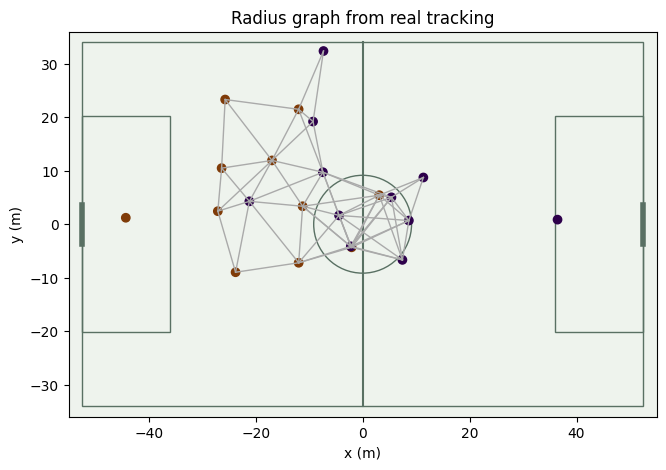

In [2]:
def make_graph(nodes,radius=15):
    nodes=nodes.sort_values('player_id');position=nodes[['x','y']].to_numpy()
    X=np.c_[position/np.array([52.5,34]),nodes.team_id.eq(1802).astype(float)]
    distance=np.linalg.norm(position[:,None]-position[None,:],axis=-1)
    A=(distance<=radius).astype(float) # includes self loops
    A=A/A.sum(axis=1,keepdims=True)
    return X,A,nodes.player_id.to_numpy()
X,A,ids=make_graph(snapshot)
display(pd.DataFrame(X,index=ids,columns=['x_scaled','y_scaled','team']))
fig,ax=plt.subplots(figsize=(9,5));pitch(ax);pos=snapshot.set_index('player_id').loc[ids,['x','y']].to_numpy()
for i,j in zip(*np.where(np.triu(A>0,1))):ax.plot(pos[[i,j],0],pos[[i,j],1],c='#aaa',lw=1)
ax.scatter(pos[:,0],pos[:,1],c=X[:,2],cmap='PuOr');ax.set_title('Radius graph from real tracking');plt.show()

## Message passing and graph readout
Average neighboring features, apply a learned linear map and nonlinearity, then pool player embeddings into a graph vector. Shared weights and symmetric pooling make this classifier invariant to row order when features and edges are permuted together. Distance/relative-velocity edge features and explicit ball nodes would enrich this minimal implementation.

In [3]:
def encode(X,A,W):return np.tanh(A@X@W)
def graph_probability(X,A,W,head,bias=0):
    H=encode(X,A,W);g=H.mean(axis=0);return 1/(1+np.exp(-np.clip(g@head+bias,-40,40)))
rng=np.random.default_rng(4);W=rng.normal(0,.1,(X.shape[1],8));head=rng.normal(0,.1,8)
embedding=encode(X,A,W);display(pd.DataFrame(embedding,index=ids).head())
permutation=rng.permutation(len(X))
assert np.isclose(graph_probability(X,A,W,head),graph_probability(X[permutation],A[np.ix_(permutation,permutation)],W,head))
print('Permutation-invariance check passed. Random weights are not EPV predictions.')

,0,1,2,3,4,5,6,7
11897,-0.010627,0.032837,-0.076271,-0.059278,0.046994,-0.020145,0.044804,-0.024377
287934,-0.158852,0.086023,-0.017431,-0.057358,-0.056208,-0.049558,0.019079,0.003939
50982,-0.054305,0.018689,-0.052488,0.052417,0.078800,0.025433,-0.049722,0.105237
50999,-0.236332,0.098342,0.082924,-0.038297,-0.176907,-0.066174,-0.009044,0.005011
51002,-0.114287,0.066750,-0.024203,-0.052994,-0.034438,-0.039754,0.022998,-0.004674


Permutation-invariance check passed. Random weights are not EPV predictions.


## Train the small GNN with explicit backpropagation
Binary cross entropy, graph pooling, tanh derivative and neighbor aggregation gradients are shown below. Training uses synthetic graphs with a synthetic feature-sign label to check that optimization works. This does **not** establish soccer performance. The same function can accept real labeled graph samples after creating an appropriate held-out split.

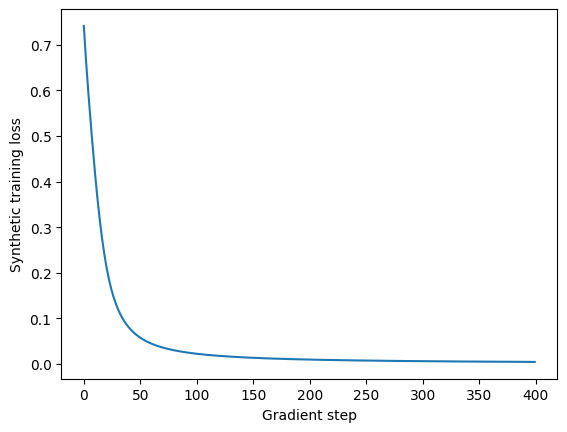

In [4]:
def train_gnn(graphs,labels,hidden=8,steps=400,lr=.1):
    rng=np.random.default_rng(11);W=rng.normal(0,.2,(graphs[0][0].shape[1],hidden));head=rng.normal(0,.2,hidden);bias=0.;losses=[]
    for step in range(steps):
        dW=np.zeros_like(W);dh=np.zeros_like(head);db=0.;loss=0.
        for (X,A),y in zip(graphs,labels):
            aggregated=A@X;H=np.tanh(aggregated@W);g=H.mean(axis=0)
            z=g@head+bias;p=1/(1+np.exp(-np.clip(z,-40,40)));error=p-y
            loss+=np.logaddexp(0,z)-y*z
            dh+=g*error;db+=error
            dH=np.broadcast_to(head*error/len(X),H.shape)
            dW+=aggregated.T@(dH*(1-H**2))
        n=len(graphs);W-=lr*dW/n;head-=lr*dh/n;bias-=lr*db/n;losses.append(loss/n)
    return W,head,bias,losses
rng=np.random.default_rng(10);toy_graphs=[];toy_labels=[]
for i in range(40):
    label=i%2;features=rng.normal(2*label-1,.3,(6,3));adjacency=np.ones((6,6))/6
    toy_graphs.append((features,adjacency));toy_labels.append(label)
trained_W,trained_head,trained_bias,losses=train_gnn(toy_graphs,toy_labels)
assert losses[-1]<losses[0]
plt.plot(losses);plt.xlabel('Gradient step');plt.ylabel('Synthetic training loss');plt.show()

## Build GraphEPV labels with a declared horizon
Bekkers' 2025 talk labels a frame positive when the team in possession scores within the next ten seconds in the same period. Require known follow-up through the horizon; censored sample endings and unknown possession must not become negative examples. Future outcomes are labels, never input features. A production implementation also needs complete event coverage and explicit period-end handling.

In [5]:
def goal_within_horizon(frames,goals,coverage_end,horizon=10):
    labels=pd.Series(np.nan,index=frames.index,dtype=float)
    for idx,r in frames.iterrows():
        end=coverage_end.get(r.period_id,-np.inf)
        if pd.isna(r.ball_owning_team_id) or r.seconds+horizon>end:continue
        eligible=goals.period.eq(r.period_id)&goals.team_id.eq(r.ball_owning_team_id)&goals.seconds.gt(r.seconds)&goals.seconds.le(r.seconds+horizon)
        labels.loc[idx]=float(eligible.any())
    return labels
toy_frames=pd.DataFrame({'period_id':[1,1,1],'seconds':[0,12,28],'ball_owning_team_id':[1,1,1]})
toy_goals=pd.DataFrame({'period':[1],'seconds':[8.],'team_id':[1]})
toy_labels=goal_within_horizon(toy_frames,toy_goals,{1:30.})
assert toy_labels.iloc[0]==1 and toy_labels.iloc[1]==0 and pd.isna(toy_labels.iloc[2])
display(toy_labels.rename('Synthetic target check'))

0    1.0
1    0.0
2    NaN
Name: Synthetic target check, dtype: float64

## Historical features and temporal identity edges
Build backward displacement and velocity without future frames. Same-player edges connect consecutive observations within a period. A one-second lag uses ten frames at this sample's native ten Hz, with an elapsed-time check. Never bridge substitutions, missing identity observations or period boundaries.

In [6]:
history=tracking.sort_values(['player_id','period_id','frame_id']).copy()
groups=history.groupby(['player_id','period_id'])
history['lag_frame']=groups.frame_id.shift(10);history['lag_time']=groups.seconds.shift(10)
valid=history.frame_id.sub(history.lag_frame).eq(10)&np.isclose(history.seconds-history.lag_time,1)
history['dx_1s']=(history.x-groups.x.shift(10)).where(valid)
history['dy_1s']=(history.y-groups.y.shift(10)).where(valid)
temporal=[]
for (pid,period),g in observed.groupby(['player_id','period_id']):
    g=g.sort_values('frame_id')
    for a,b in zip(g.itertuples(),list(g.itertuples())[1:]):
        if b.frame_id-a.frame_id==1 and 0<b.seconds-a.seconds<.2:
            temporal.append((pid,period,a.frame_id,b.frame_id,b.seconds-a.seconds))
temporal=pd.DataFrame(temporal,columns=['player_id','period','source_frame','target_frame','dt'])
assert temporal.target_frame.gt(temporal.source_frame).all()
display(history[['player_id','frame_id','dx_1s','dy_1s']].dropna().head());display(temporal.head())

,player_id,frame_id,dx_1s,dy_1s
67693,11897,50,-0.20,0.15
67694,11897,51,-0.24,0.20
67695,11897,52,-0.27,0.24
67696,11897,53,-0.31,0.30
67697,11897,54,-0.36,0.35


,player_id,period,source_frame,target_frame,dt
0,11897,1,40,41,0.1
1,11897,1,41,42,0.1
2,11897,1,42,43,0.1
3,11897,1,43,44,0.1
4,11897,1,44,45,0.1


## Temporal encoders: recurrence, convolution and attention
After encoding each spatial graph, apply a historical sequence model. Below are minimal forward calculations for a recurrent state, causal convolution and masked attention. Random parameters illustrate tensor mechanics only; they are not trained forecasts or EPV. The recurrence is a plain tanh RNN rather than a GRU. Identity-edge message passing is another approach, rather than the same architecture under a different name.

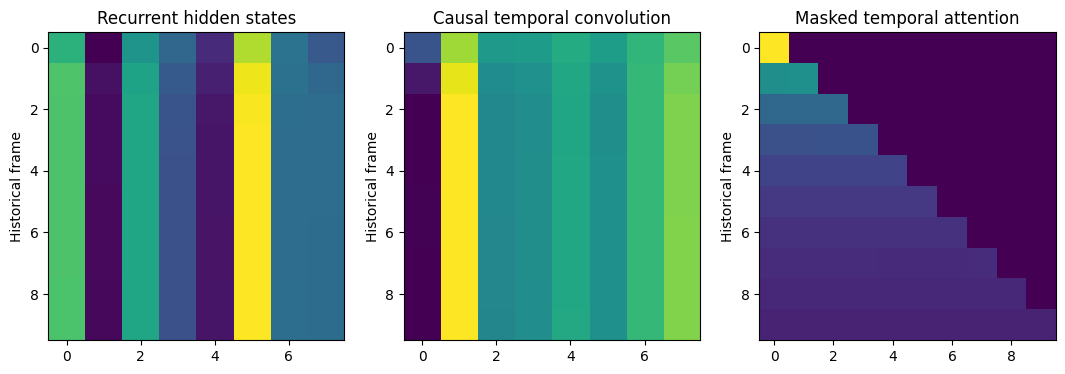

In [7]:
available=observed.groupby('frame_id').size();available=set(available[available.eq(22)].index)
start=next(f for f in sorted(available) if all(f+j in available for j in range(10)))
Z=[]
for f in range(start,start+10):
    Xi,Ai,_=make_graph(observed[observed.frame_id.eq(f)]);Z.append(encode(Xi,Ai,W).mean(axis=0))
Z=np.array(Z);d=Z.shape[1];rng=np.random.default_rng(9)
U=rng.normal(0,.1,(d,d));R=rng.normal(0,.1,(d,d));state=np.zeros(d);states=[]
for z in Z:state=np.tanh(z@U+state@R);states.append(state.copy())
kernel=np.array([.6,.3,.1]);convolution=np.array([sum(kernel[k]*Z[t-k] for k in range(min(3,t+1))) for t in range(len(Z))])
scores=Z@Z.T/np.sqrt(d);mask=np.triu(np.ones_like(scores,dtype=bool),1);scores[mask]=-np.inf
attention=np.exp(scores-scores.max(axis=1,keepdims=True));attention/=attention.sum(axis=1,keepdims=True);context=attention@Z
assert np.allclose(attention[mask],0)
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,data,title in zip(axs,[np.array(states),convolution,attention],['Recurrent hidden states','Causal temporal convolution','Masked temporal attention']):ax.imshow(data,aspect='auto');ax.set_title(title);ax.set_ylabel('Historical frame')
plt.show()

## Evaluation and extensions
Split by whole matches or independent possessions, with no overlapping history/outcome windows across splits. Test calibration and compare location-only, tabular, static-graph and temporal baselines on the **same** target. Larger temporal models need far more than this sample. Learned attention is not causal importance. Receiver prediction, defensive attribution, counterattack success and trajectory forecasting need their own targets and losses; the binary scorer above does not reproduce TacticAI, DEFCON or a trajectory generator. Sources: [GraphEPV talk](https://rawcdn.githack.com/UnravelSports/keynotes/main/html/20250607-PyData-London.html), [counterattack GNN](https://arxiv.org/abs/2411.17450), [temporal architectures](https://pytorch-geometric-temporal.readthedocs.io/en/latest/modules/root.html).